In [ ]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline

In [78]:
FILE_PATH = 'UsedCars.csv'
data = pd.read_csv(FILE_PATH)
data.head(10)

,age_years,mileage_km,engine_l,power_hp,brand,fuel_type,transmission,accident_history,price_azn
0,11,97064.0,NaN,77,Hyundai,hybrid,manual,no,3805
1,10,74340.0,NaN,135,BMW,petrol,automatic,no,4851
2,6,69312.0,1.4,95,Toyota,petrol,NaN,no,5379
3,8,126280.0,NaN,89,Kia,hybrid,automatic,no,5471
4,2,42026.0,1.4,98,BMW,hybrid,automatic,no,6740
5,11,89859.0,2.0,120,Hyundai,petrol,automatic,yes,7922
6,6,124854.0,3.0,196,Toyota,diesel,automatic,no,9250
7,4,70952.0,1.8,95,BMW,petrol,automatic,no,9778
8,15,248400.0,1.8,90,Hyundai,hybrid,automatic,no,9858
9,11,153076.0,2.0,140,BMW,hybrid,automatic,no,10011


In [79]:
data.shape

(300, 9)

In [80]:
data.dtypes

age_years             int64
mileage_km          float64
engine_l            float64
power_hp              int64
brand                   str
fuel_type               str
transmission            str
accident_history        str
price_azn             int64
dtype: object

In [81]:
data.isna().sum()

age_years            0
mileage_km          17
engine_l            16
power_hp             0
brand                0
fuel_type           13
transmission        10
accident_history     0
price_azn            0
dtype: int64

In [82]:
data.describe()

,age_years,mileage_km,engine_l,power_hp,price_azn
count,300.000000,283.000000,284.000000,300.000000,300.000000
mean,7.850000,118302.176678,1.901761,123.270000,27806.573333
std,4.147066,73652.009931,0.581484,39.903861,9772.778467
min,1.000000,8659.000000,1.200000,57.000000,3805.000000
25%,4.000000,54862.500000,1.400000,93.000000,21865.500000
50%,8.000000,112308.000000,1.800000,113.000000,27458.500000
75%,11.000000,166869.500000,2.500000,151.250000,34844.750000
max,15.000000,334305.000000,3.000000,218.000000,51396.000000


In [83]:
data['price_azn'].min()

np.int64(3805)

In [84]:
data['price_azn'].max()

np.int64(51396)

In [85]:
data['price_azn'].mean()

np.float64(27806.573333333334)

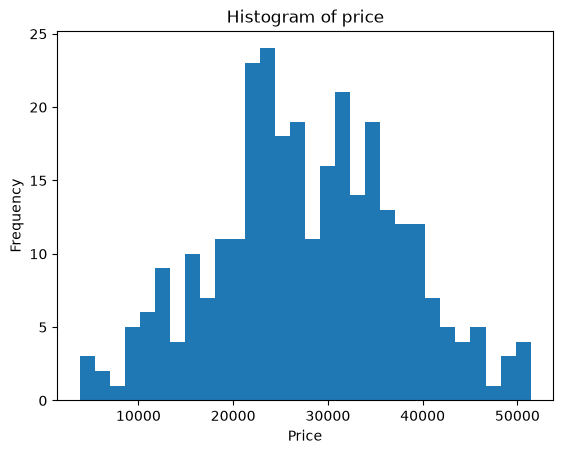

In [86]:
plt.figure()
plt.hist(data['price_azn'], bins=30)
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.title('Histogram of price')
plt.show()

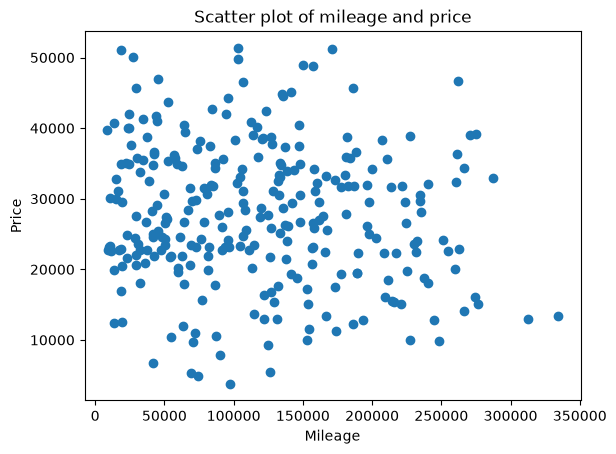

In [87]:
plt.figure()
plt.scatter(data['mileage_km'], data['price_azn'])
plt.xlabel('Mileage')
plt.ylabel('Price')
plt.title('Scatter plot of mileage and price')
plt.show()

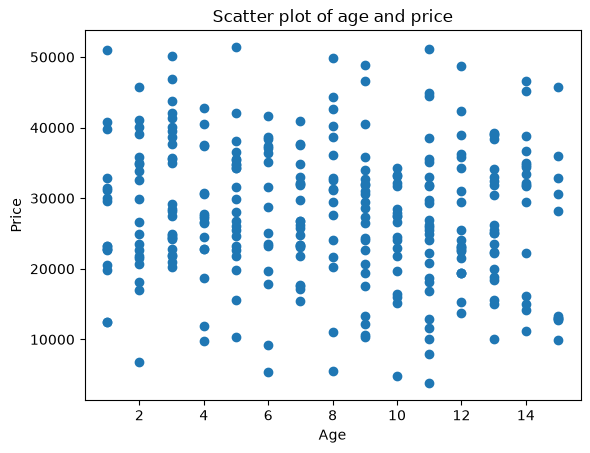

In [88]:
plt.figure()
plt.scatter(data['age_years'], data['price_azn'])
plt.xlabel('Age')
plt.ylabel('Price')
plt.title('Scatter plot of age and price')
plt.show()

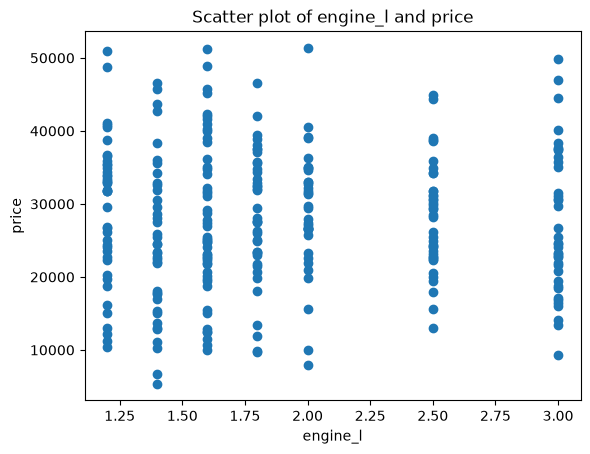

In [89]:
plt.figure()
plt.scatter(data['engine_l'], data['price_azn'])
plt.xlabel('engine_l')
plt.ylabel('price')
plt.title('Scatter plot of engine_l and price')
plt.show()

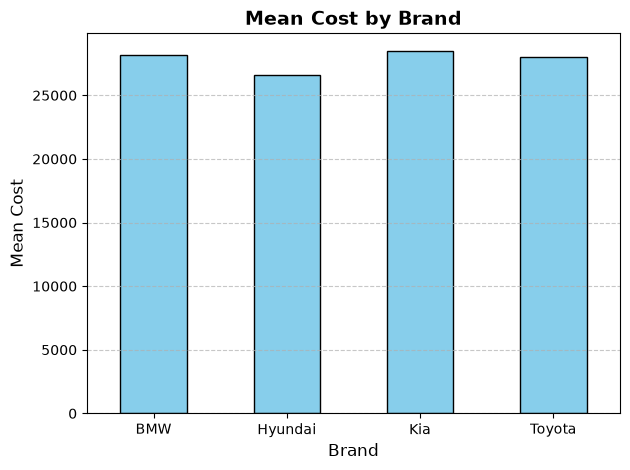

In [90]:
mean_cost_by_brand = data.groupby('brand')['price_azn'].mean()


ax = mean_cost_by_brand.plot(kind='bar', color='skyblue', edgecolor='black')


plt.title('Mean Cost by Brand', fontsize=14, fontweight='bold')
plt.xlabel('Brand', fontsize=12)
plt.ylabel('Mean Cost', fontsize=12)
plt.xticks(rotation=0)  
plt.grid(axis='y', linestyle='--', alpha=0.7)


plt.tight_layout()
plt.show()

In [91]:
data.head()

,age_years,mileage_km,engine_l,power_hp,brand,fuel_type,transmission,accident_history,price_azn
0,11,97064.0,NaN,77,Hyundai,hybrid,manual,no,3805
1,10,74340.0,NaN,135,BMW,petrol,automatic,no,4851
2,6,69312.0,1.4,95,Toyota,petrol,NaN,no,5379
3,8,126280.0,NaN,89,Kia,hybrid,automatic,no,5471
4,2,42026.0,1.4,98,BMW,hybrid,automatic,no,6740


In [92]:
from sklearn.pipeline import make_pipeline


target_column = 'price_azn'


numeric_columns = ['age_years','mileage_km', 'engine_l', 'power_hp']
categorical_columns = ['brand', 'fuel_type', 'transmission', 'accident_history']

data['mileage_per_year'] = data['mileage_km']/data['age_years']



X = data.drop(columns=[target_column])
y = data[target_column]



X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)




num_features = numeric_columns + ['mileage_per_year']





numeric_transformer = Pipeline(

    steps=[

        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())

    ]


)


categorical_transformer = Pipeline(

    steps = [

('imputer', SimpleImputer(strategy='most_frequent')),
('onehot', OneHotEncoder())


]

)



preprocessor = ColumnTransformer(

    transformers=[
        ('num', numeric_transformer, num_features),
        ('cat', categorical_transformer, categorical_columns)]

)



linreg_model = Pipeline(

    steps=[

        ('prepocessor', preprocessor),
        ('model', LinearRegression())
    

    ]

)



linreg_model.fit(X_train, y_train)





y_pred = linreg_model.predict(X_test)




y_test[10:20], y_pred[10:20]






(237    35783
 57     19668
 218    34274
 45     17736
 182    31146
 221    34385
 289    45754
 211    33185
 148    27327
 165    29465
 Name: price_azn, dtype: int64,
 array([28213.3370812 , 29596.21022615, 26257.97682871, 29605.03517588,
        28579.46296072, 26144.00798864, 26345.76695859, 25871.04977052,
        27769.95849004, 27551.77781954]))